# Project
## CIC6314 Artificial Intelligence 

**Tutorial section: TT3L**

| | Student ID     | Student Name                | 
|--:|:-------------|:----------------------------|
| 1 | 1211103412   | Lai Chi Nyet                |
| 2 | 1211104955   | Joyce Woo Kai Xuan          |  
| 3 | 1211104977   | Toh Kai Ru                  | 
| 4 | 1211104786   | Nicholas Tan Zhi Xuan       |  

## Introduction

The emergence of short-term rental services such as Airbnb has revolutionized the international hospitality sector, offering travelers various lodging choices and enabling property owners to generate extra income. The cost of Airbnb listings is affected by various elements such as location, property type, amenities, and host attributes. For hosts, setting the appropriate price for a listing can be a challenging endeavor, necessitating understanding of market dynamics, rivalry, and guest tastes. On the other hand, travelers aim to comprehend the prices of different listings to make well-informed choices when booking.

This project aims to develop a machine learning model to predict the nightly rate of an Airbnb listing according to its characteristics. The dataset utilized in this project encompasses various attributes tied to listings, including property type, location, amenities, and reviews, along with the pricing.

The aim of this project is to create a regression model that reliably predict the price of Airbnb listings. The target variable, price, is a continuous variable, which categorizes it as a regression issue. By forecasting the price, the model can aid hosts in refining their pricing tactics and support guests in approximating the cost of different listings prior to booking.

The evaluation of the model's performance will utilize standard regression metrics like Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R² (Coefficient of Determination). The intended result of this project is to develop a model capable of accurately forecasting prices based on a specified set of listing characteristics, delivering practical benefits to both hosts and guests on the Airbnb platform.

## AI Problem Formulation

#### Regression Problem
The goal of this project is to develop a machine learning model to predict the nightly price of Airbnb listings based on various features such as location, property type, room type, availability, reviews, amenities etc. Given the continuous nature of the price, this is a regression problem.

Objective:
- Predict the price of Airbnb listings in the Boston area using available features.
- Target Variable: price (a continuous numeric variable).
  
Input Features
- Numerical: accommodates, bathrooms, bedrooms, beds, availability_30, availability_60, availability_90, availability_365, number_of_reviews, review_scores_rating, review_scores_accuracy, review_scores_cleanliness, review_scores_checkin, review_scores_communication, review_scores_location, review_scores_value.
- Categorical: property_type, room_type, neighbourhood_cleansed, instant_bookable, cancellation_policy.

Evaluation Metrics
- Mean Absolute Error (MAE): Measures average prediction error.
- Root Mean Squared Error (RMSE): Penalizes larger errors more than MAE.
- R²: Indicates how well the model explains the variance in price.
  
Approach
- Data Preprocessing: Clean data, handle missing values, and encode categorical variables.
- Modeling: Train and compare three regression models: K-Nearest Neighbors (KNN), Linear Regression, and Random Forest.
  
Challenges
- Handling missing or inconsistent data.
- Identifying the most influential features for price prediction.
  
Expected Outcome
- A regression model that accurately predicts Airbnb prices, providing useful insights for hosts and guests.

## Data Preparation and Processing Pipeline

Preparation of data or processing is a significant part of any machine learning project. Here deal with the Boston Airbnb dataset for predicting night price against an Airbnb listing. Below are described cleaning, transformation, and preprocessing that have to be performed for preparing data into regression modeling shape.

#### Import Necessary Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, root_mean_squared_error

#### Load Dataset

Load the dataset into a pandas DataFrame. This allows to perform various operations like cleaning, feature selection, and transformation:

In [2]:
df = pd.read_csv('listings.csv')

This reads the dataset from the CSV file into a pandas DataFrame, which is a table-like structure that allows for efficient data handling.

#### Inspect Data

Once the data is loaded, check the basic structure of the dataset, including the number of rows and columns, and ensure that the correct data types are assigned to each column:

This helps us understand the number of rows and columns, as well as the types of data in each column (e.g., numerical, categorical).

In [3]:
df.info()
df.shape

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3585 entries, 0 to 3584
Data columns (total 95 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   id                                3585 non-null   int64  
 1   listing_url                       3585 non-null   object 
 2   scrape_id                         3585 non-null   int64  
 3   last_scraped                      3585 non-null   object 
 4   name                              3585 non-null   object 
 5   summary                           3442 non-null   object 
 6   space                             2528 non-null   object 
 7   description                       3585 non-null   object 
 8   experiences_offered               3585 non-null   object 
 9   neighborhood_overview             2170 non-null   object 
 10  notes                             1610 non-null   object 
 11  transit                           2295 non-null   object 
 12  access

(3585, 95)

After loading the data, explore the dataset by reviewing the first few rows to understand its structure and identify any issues:

In [4]:
df.head()

,id,listing_url,scrape_id,last_scraped,name,summary,space,description,experiences_offered,neighborhood_overview,...,review_scores_value,requires_license,license,jurisdiction_names,instant_bookable,cancellation_policy,require_guest_profile_picture,require_guest_phone_verification,calculated_host_listings_count,reviews_per_month
0,12147973,https://www.airbnb.com/rooms/12147973,20160906204935,2016-09-07,Sunny Bungalow in the City,"Cozy, sunny, family home. Master bedroom high...",The house has an open and cozy feel at the sam...,"Cozy, sunny, family home. Master bedroom high...",none,"Roslindale is quiet, convenient and friendly. ...",...,NaN,f,NaN,NaN,f,moderate,f,f,1,NaN
1,3075044,https://www.airbnb.com/rooms/3075044,20160906204935,2016-09-07,Charming room in pet friendly apt,Charming and quiet room in a second floor 1910...,Small but cozy and quite room with a full size...,Charming and quiet room in a second floor 1910...,none,"The room is in Roslindale, a diverse and prima...",...,9.0,f,NaN,NaN,t,moderate,f,f,1,1.30
2,6976,https://www.airbnb.com/rooms/6976,20160906204935,2016-09-07,Mexican Folk Art Haven in Boston,"Come stay with a friendly, middle-aged guy in ...","Come stay with a friendly, middle-aged guy in ...","Come stay with a friendly, middle-aged guy in ...",none,The LOCATION: Roslindale is a safe and diverse...,...,10.0,f,NaN,NaN,f,moderate,t,f,1,0.47
3,1436513,https://www.airbnb.com/rooms/1436513,20160906204935,2016-09-07,Spacious Sunny Bedroom Suite in Historic Home,Come experience the comforts of home away from...,Most places you find in Boston are small howev...,Come experience the comforts of home away from...,none,Roslindale is a lovely little neighborhood loc...,...,10.0,f,NaN,NaN,f,moderate,f,f,1,1.00
4,7651065,https://www.airbnb.com/rooms/7651065,20160906204935,2016-09-07,Come Home to Boston,"My comfy, clean and relaxing home is one block...","Clean, attractive, private room, one block fro...","My comfy, clean and relaxing home is one block...",none,"I love the proximity to downtown, the neighbor...",...,10.0,f,NaN,NaN,f,flexible,f,f,1,2.25


### Data Preprocessing

#### Keep Necessary Columns

In order to focus on the most relevant information, we select a subset of columns that are necessary for predicting the nightly price (price). The selected columns include:

- property_type, room_type, accommodates, bathrooms, bedrooms, beds, amenities, availability_* columns, neighbourhood_cleansed, number_of_reviews, review_scores_*, instant_bookable, and cancellation_policy.

We drop the unnecessary columns to streamline the dataset:

In [5]:
# Columns to keep
columns_to_keep = ['property_type', 'room_type', 'accommodates', 'bathrooms', 'bedrooms', 'beds', 'amenities', 'availability_30',
                   'availability_60', 'availability_90', 'availability_365', 'neighbourhood_cleansed', 'number_of_reviews', 
                   'review_scores_rating', 'review_scores_accuracy', 'review_scores_cleanliness', 'review_scores_checkin',
                   'review_scores_communication', 'review_scores_location', 'review_scores_value', 'instant_bookable', 
                   'cancellation_policy', 'price']
# Keep only the selected columns
df = df[columns_to_keep]

In [6]:
df.head()

,property_type,room_type,accommodates,bathrooms,bedrooms,beds,amenities,availability_30,availability_60,availability_90,...,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,instant_bookable,cancellation_policy,price
0,House,Entire home/apt,4,1.5,2.0,3.0,"{TV,""Wireless Internet"",Kitchen,""Free Parking ...",0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,f,moderate,$250.00
1,Apartment,Private room,2,1.0,1.0,1.0,"{TV,Internet,""Wireless Internet"",""Air Conditio...",26,54,84,...,94.0,10.0,9.0,10.0,10.0,9.0,9.0,t,moderate,$65.00
2,Apartment,Private room,2,1.0,1.0,1.0,"{TV,""Cable TV"",""Wireless Internet"",""Air Condit...",19,46,61,...,98.0,10.0,9.0,10.0,10.0,9.0,10.0,f,moderate,$65.00
3,House,Private room,4,1.0,1.0,2.0,"{TV,Internet,""Wireless Internet"",""Air Conditio...",6,16,26,...,100.0,10.0,10.0,10.0,10.0,10.0,10.0,f,moderate,$75.00
4,House,Private room,2,1.5,1.0,2.0,"{Internet,""Wireless Internet"",""Air Conditionin...",13,34,59,...,99.0,10.0,10.0,10.0,10.0,9.0,10.0,f,flexible,$79.00


#### Handle Missing Values

Handling missing values is one of the most important preprocessing steps. Missing data can cause models to perform poorly or even fail to train. In this project, we first check for missing values in the dataset:

In [7]:
# Adjust display settings
pd.set_option('display.max_rows', None)
# Check for missing values
print(df.isnull().sum())

property_type                    3
room_type                        0
accommodates                     0
bathrooms                       14
bedrooms                        10
beds                             9
amenities                        0
availability_30                  0
availability_60                  0
availability_90                  0
availability_365                 0
neighbourhood_cleansed           0
number_of_reviews                0
review_scores_rating           813
review_scores_accuracy         823
review_scores_cleanliness      818
review_scores_checkin          820
review_scores_communication    818
review_scores_location         822
review_scores_value            821
instant_bookable                 0
cancellation_policy              0
price                            0
dtype: int64


If missing values are found, decide to drop rows with any missing values. Alternatively, other imputation methods like filling missing values with the median or mode can be used, but for simplicity, remove rows with missing values in this case:

In [8]:
# Drop rows with any missing values
df = df.dropna()

In [9]:
# Adjust display settings
pd.set_option('display.max_rows', None)
# Check for missing values
print(df.isnull().sum())

property_type                  0
room_type                      0
accommodates                   0
bathrooms                      0
bedrooms                       0
beds                           0
amenities                      0
availability_30                0
availability_60                0
availability_90                0
availability_365               0
neighbourhood_cleansed         0
number_of_reviews              0
review_scores_rating           0
review_scores_accuracy         0
review_scores_cleanliness      0
review_scores_checkin          0
review_scores_communication    0
review_scores_location         0
review_scores_value            0
instant_bookable               0
cancellation_policy            0
price                          0
dtype: int64


#### Clean Column Names

The price column contains non-numeric characters like dollar signs ($) and commas (,), which need to be removed before converting the column into a numeric data type. Use regular expressions to clean the price column and convert it into a float:

In [10]:
# Remove $ and commas from the price column and convert to float
df['price'] = df['price'].replace('[\$,]', '', regex=True).astype(float)

In [11]:
df[['price']].head()

,price
1,65.0
2,65.0
3,75.0
4,79.0
5,75.0


#### Handle Outliers

This step is important for identifying extreme values or outliers in the price column. Extreme values, such as listings with prices that are unusually low or high, can distort the training of machine learning models, leading to inaccurate predictions. By checking the highest and lowest values, we can determine whether any outliers need to be removed or investigated further before training the model.

In [12]:
# Display the highest and lowest values in the 'price' column
max_price = df['price'].max()
min_price = df['price'].min()

print(f"Highest price: {max_price}")
print(f"Lowest price: {min_price}")

Highest price: 1300.0
Lowest price: 11.0


The describe() function provides key statistical insights into the distribution of the price column, such as the mean, median, standard deviation, minimum, and maximum values. This helps us understand how the prices are spread across the dataset, whether they are normally distributed, and if there are any skewed patterns. It also highlights potential inconsistencies, like an unusually high or low price that may not be representative of typical listings. This step gives us a clear overview of the data, ensuring we are working with a reliable and representative dataset.

In [13]:
# Display all descriptive statistics for the 'price' column
price_details = df['price'].describe()

# Print the details
price_details

count    2734.000000
mean      166.807974
std       113.361081
min        11.000000
25%        85.000000
50%       145.000000
75%       215.000000
max      1300.000000
Name: price, dtype: float64

Filtering extreme values involves removing listings with prices that fall outside a reasonable range. These outliers can heavily influence the performance of regression models by creating misleading relationships between features and the target variable (price). For example, properties with extremely high prices could be luxury listings or error entries, and very low-priced listings might be promotional offers or incorrect data. Removing these outliers ensures the model is trained on data that reflects the typical pricing patterns of the majority of Airbnb listings, leading to more accurate predictions and better generalization.

In [14]:
df = df[(df['price'] > 30) & (df['price'] < 400)]

#### Feature Engineering

Feature engineering helps improve the performance of the models. In this case, create a new feature, amenities_count, which counts the number of amenities listed for each property. This is derived from the amenities column by splitting the string on commas and counting the resulting values. After extracting the amenities count, we drop the original amenities column:

In [15]:
# Extract amenities count from the 'amenities' column
df['amenities_count'] = df['amenities'].apply(lambda x: len(x.split(',')) if isinstance(x, str) else 0)
# Drop the 'amenities' column
df.drop(columns=['amenities'], inplace=True)

In [16]:
df.head()

,property_type,room_type,accommodates,bathrooms,bedrooms,beds,availability_30,availability_60,availability_90,availability_365,...,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,instant_bookable,cancellation_policy,price,amenities_count
1,Apartment,Private room,2,1.0,1.0,1.0,26,54,84,359,...,10.0,9.0,10.0,10.0,9.0,9.0,t,moderate,65.0,21
2,Apartment,Private room,2,1.0,1.0,1.0,19,46,61,319,...,10.0,9.0,10.0,10.0,9.0,10.0,f,moderate,65.0,18
3,House,Private room,4,1.0,1.0,2.0,6,16,26,98,...,10.0,10.0,10.0,10.0,10.0,10.0,f,moderate,75.0,23
4,House,Private room,2,1.5,1.0,2.0,13,34,59,334,...,10.0,10.0,10.0,10.0,9.0,10.0,f,flexible,79.0,14
5,Condominium,Private room,2,1.0,1.0,1.0,5,28,58,58,...,10.0,10.0,10.0,10.0,9.0,10.0,f,flexible,75.0,13


#### Encode Categorical Variables

Regression models cannot directly handle categorical data, so need to convert categorical variables into numerical representations. Use one-hot encoding for columns such as property_type, room_type, neighbourhood_cleansed, instant_bookable, and cancellation_policy. The drop_first=True argument avoids the multicollinearity issue by dropping one of the dummy variables for each categorical feature:

In [17]:
# One-hot encode categorical variables
categorical_features = ['property_type', 'room_type', 'neighbourhood_cleansed', 'instant_bookable', 'cancellation_policy']
df = pd.get_dummies(df, columns=categorical_features, drop_first=True)

#### Normalize Numerical Variables

To ensure that all numerical features have the same scale, we apply normalization using the MinMaxScaler. This scales features such as accommodates, bathrooms, bedrooms, beds, and review scores between 0 and 1. This scaling ensures that the model treats each feature equally, without any one feature dominating due to larger values:

In [18]:
# Normalize numerical features using MinMaxScaler
scaler = MinMaxScaler()
numerical_features = ['accommodates', 'bathrooms', 'bedrooms', 'beds', 'availability_30','availability_60', 'availability_90',
                      'availability_365', 'number_of_reviews', 'review_scores_rating', 'review_scores_accuracy', 'review_scores_cleanliness', 
                      'review_scores_checkin', 'review_scores_communication', 'review_scores_location', 'review_scores_value' ]
df[numerical_features] = scaler.fit_transform(df[numerical_features])

#### Create Target Variable

Split the data into training and test sets using train_test_split() from sklearn.model_selection. The training set is used to train the models, while the test set is used to evaluate their performance:

In [19]:
# Regression target: price
X = df.drop(['price'], axis=1)
y = df['price']

#### Train-Test Split

In [20]:
#Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [21]:
X_train.shape

(2101, 58)

In [22]:
y_train.shape[0]

2101

In [23]:
X_test.shape

(526, 58)

## AI Models Applied

In this project, three different regression models were applied to predict the nightly price of Airbnb listings in the Boston area. The models chosen for this task are K-Nearest Neighbors (KNN), Linear Regression, and Random Forest Regressor. Below is a description of each model, its mechanism, and why it was selected for this regression task.

**1. K-Nearest Neighbors (KNN)**

Mechanism:
K-Nearest Neighbors(KNN) is a very simple instance-based learning algorithm. It simply looks in the feature space for the k most similar data points to a given query point and predicts the target variable-for this case, the nightly price-by averaging over the neighbors. Distance between the points can be calculated by using Euclidean distance, although other distance metrics may also be used.

How It Works:

- Instead of learning from the data, the model just memorizes the dataset and makes predictions simply based on what happens around that query point in the local environment.
- For instance, in a regression task, KNN tries to predict target values by simply averaging the values of the k nearest neighbors.
  
Why It Was Used:
- KNN is simple to implement and intuitive, and predictions are based on local relationships that might be useful in finding similar listings based on features such as room_type, location, and amenities_count.
- Non-parametric: KNN does not assume anything about the underlying distribution of data, hence can be quite versatile for a wide range of data types.
  
Limitations:
- KNN can be computationally very expensive with large datasets since the distance to all data points needs to be computed.
- It is sensitive to the choice of k. When k is too small, it can have high variance or overfit.

**2. Linear Regression**

Mechanism:
Linear Regression probably is the simplest and one of the most widely used regression methods. It assumes a linear relationship between independent variables or features and the target variable. The model tries to fit a straight line-or hyperplane in higher dimensions-that minimizes the sum of squared errors between the predicted values and the actual values in the training data.

How It Works:
- It minimizes the sum of squared residuals to find the best fitting line; therefore, it finds the estimators - weights of coefficients of each feature. The difference between the predicted price and the real price is minimum.
- The equation of the line is: price = β0 + β1 ⋅ accommodates + β2 ⋅ bathrooms +... + βn ⋅ feature_n

Why It Was Used:
- Easy to interpret and understand: Linear regression is intuitive from its nature, and that makes it easy to understand how each feature affects the target variable. This can also be helpful in choosing the most influential features, like accommodates, bathrooms, and review_scores, affecting the price.
- It is efficient when working with small datasets, or if the relationships among the features and targets are approximately linear.

Limitations:

- Assumes linearity between features and the target, which may be an unrealistic assumption for complex data.
- If a large number of features or multicollinearity exists, overfitting can very easily occur.

**3. Random Forest Regressor**

Mechanism:
Random Forest is an ensemble learning method that runs multiple decision trees together, keeping overfitting low and accuracy of prediction high. Each of these trees is grown on a random subset of the data and thus predictions are to be done averaging the prediction done by different individual trees.

How It Works:
- Bootstrapping: This is done by training every tree on a random sample of the dataset with replacement. Random Feature Selection: In the course of building each tree, Random Forest chooses a random subset of features on which to split at every node, reducing correlation among trees and preventing overfitting.
- Prediction: The final prediction in a regression task is given by the average of all the predictions of the trees.
  
Why It Was Used:
- Non-linear relationships: Random Forest is capable of modeling complex, non-linear relationships between features and target variables, which is important for predicting prices, as the relationship between features and price may not be linear.
- Avoids overfitting: It averages over many trees so reduces the variance of an individual decision tree. Therefore, a random forest is less prone to overfitting compared to a single decision tree.
- Feature Importance: Using Random Forest features importance, which is useful for understanding the key drivers of Airbnb prices.

Limitations:
- Computationally intensive: can be slow to train and predict, especially with large datasets and a lot of trees.
- Less interpretable: though decision trees are easy to interpret, Random Forests involve many trees, which makes the model harder to interpret.

By comparing the performance of these three models, we can determine which one best predicts the nightly price of Airbnb listings based on the available features.

## Experiments

### Regression

The primary objective of the experiments is to evaluate the effectiveness of three machine learning models—K-Nearest Neighbors (KNN), Linear Regression, and Random Forest Regressor—in predicting Airbnb listing prices in Boston. By conducting a systematic evaluation using consistent metrics and experimental setups, we aim to determine the best-performing model for this task and understand their behavior on the given dataset.



#### Regression Problem: K-Nearest Neighbors

The KNeighborsRegressor from scikit-learn was used with n_neighbors=12. This value of k was chosen after testing multiple values (e.g., 5, 10, 12, 15) and selecting the one with the best performance on a validation set.The training data (X_train, y_train) was standardized to ensure all features contributed equally to the Euclidean distance calculation:

In [24]:
# Train KNN Regressor
knn_regressor = KNeighborsRegressor(n_neighbors=12)  
knn_regressor.fit(X_train, y_train)

KNeighborsRegressor(n_neighbors=12)

## Results

The model was used to predict prices on the test data (X_test). Predictions were compared to the actual prices (y_test) to compute the MAE, RMSE, and R² metrics:

In [25]:
# Predict and Evaluate
y_pred = knn_regressor.predict(X_test)
mae_knn = mean_absolute_error(y_test, y_pred)
rmse_knn = root_mean_squared_error(y_test, y_pred)  
r2_knn = r2_score(y_test, y_pred)

In [26]:
print(f"MAE: {mae_knn}")
print(f"RMSE: {rmse_knn}")
print(f"R²: {r2_knn}")

MAE: 43.14432826362484
RMSE: 56.93900822351773
R²: 0.5500426034502


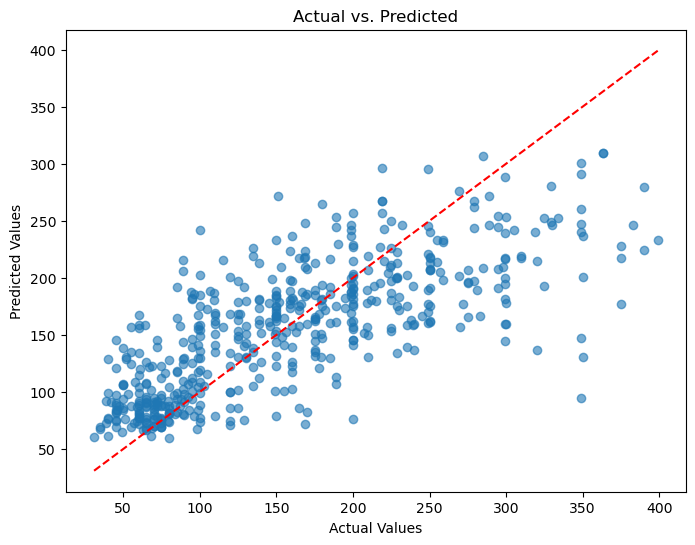

In [27]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], '--', color='red')
plt.title('Actual vs. Predicted')
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.show()

**K-Nearest Neighbors (KNN)**

Performance Metrics:
- MAE: \$43.14
  - This indicates that, on average, the KNN model's predictions deviated from the actual listing prices by \$43.14.
- RMSE: \$56.94
  - The relatively high RMSE suggests that KNN struggled with large prediction errors, likely due to its sensitivity to outliers in the dataset.
- R²: 0.55
  - The model explained only 55% of the variance in the target variable (price), showing limited explanatory power compared to other models.

Actual vs. Predicted Scatter Plots:

The scatter plots for each model showed the relationship between actual prices (y_test) and predicted prices.

KNN: The plot showed significant deviation from the diagonal, particularly for higher-priced listings, highlighting its poor generalization.

Observations:
- KNN’s performance was suboptimal. Its reliance on local patterns caused it to struggle when generalizing to unseen data.
- Despite scaling the features and optimizing the number of neighbors (k=12), the model was unable to effectively capture complex interactions or global trends in the data.
- The model performed particularly poorly for listings with higher prices, as evidenced by the scatter plot, where predictions for higher-priced listings deviated significantly from the actual values.
  
Interpretation:
- KNN's dependency on proximity in feature space works well for datasets with simple relationships, but the complexity of the Airbnb dataset (with mixed numerical and categorical features) limits its effectiveness.
- This model is computationally expensive for larger datasets, as it must compute distances to all points in the dataset during prediction.

#### Regression Problem: Linear Regression

The LinearRegression class from scikit-learn was used.No additional hyperparameters were tuned, as the model's simplicity does not require extensive configuration.The training data (X_train, y_train) was fitted to the model:

In [28]:
# Train Linear Regression Model
linear_reg = LinearRegression()
linear_reg.fit(X_train, y_train)

LinearRegression()

Predictions on the test data (X_test) were generated. Performance was evaluated using MAE, RMSE, and R² metrics:

In [29]:
# Predict and Evaluate
y_pred = linear_reg.predict(X_test)
mae_linear_reg = mean_absolute_error(y_test, y_pred)
rmse_linear_reg = root_mean_squared_error(y_test, y_pred) 
r2_linear_reg = r2_score(y_test, y_pred)

In [30]:
print(f"MAE: {mae_linear_reg}")
print(f"RMSE: {rmse_linear_reg}")
print(f"R²: {r2_linear_reg}")

MAE: 33.14103714169967
RMSE: 44.7517051777446
R²: 0.7220473783499048


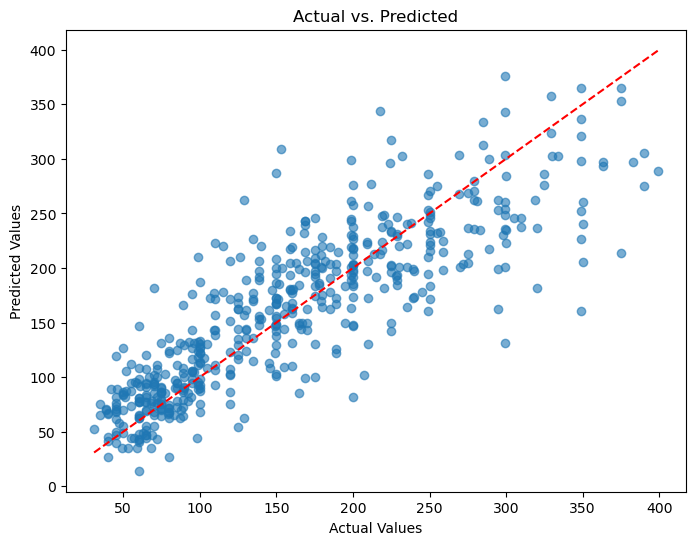

In [31]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], '--', color='red')
plt.title('Actual vs. Predicted')
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.show()

**Linear Regression**

Performance Metrics:
- MAE: \$33.14 
  - Linear Regression had the lowest mean absolute error among all models, demonstrating its ability to make accurate predictions with minimal deviation.
- RMSE: \$44.75
  - The model also achieved the lowest RMSE, indicating that it effectively minimized larger prediction errors.
- R²: 0.72
  - The model explained 72% of the variance in listing prices, the highest among all models, making it the best-performing model in terms of explanatory power.

Actual vs. Predicted Scatter Plots:

The scatter plots for each model showed the relationship between actual prices (y_test) and predicted prices.

Linear Regression: Most points aligned closely with the ideal diagonal line, reflecting high accuracy.

Observations:
- Linear Regression excelled in capturing the general trends in the dataset, providing predictions that closely aligned with the actual prices.
- Its simplicity and interpretability made it a strong baseline model, and the assumption of linearity between features and the target variable appears valid for this dataset.
- The scatter plot of actual vs. predicted prices showed that most points were concentrated along the ideal diagonal line, indicating high accuracy.
  
Interpretation:
- Linear Regression performed exceptionally well, likely because the dataset features, such as room_type, number_of_bedrooms, and review_scores_rating, have linear relationships with price.
- While it is unable to capture complex, non-linear interactions, these interactions were not dominant in this dataset, allowing the model to achieve strong performance.

#### Regression Problem: Random Forest Regression

The following hyperparameters were selected based on a grid search:
- n_estimators=100 (number of trees in the forest).
- max_depth=10 (maximum depth of each tree).
  
These parameters were chosen to balance performance and computation time.

The RandomForestRegressor from scikit-learn was trained on the training data (X_train, y_train):

In [32]:
# Train Random Forest Regression Model
rf_regressor = RandomForestRegressor(random_state=42, n_estimators=100, max_depth=10)
rf_regressor.fit(X_train, y_train)

RandomForestRegressor(max_depth=10, random_state=42)

Predictions were made on the test set (X_test). MAE, RMSE, and R² metrics were calculated for comparison:

In [33]:
# Predict and Evaluate
y_pred = rf_regressor.predict(X_test)
mae_rf = mean_absolute_error(y_test, y_pred)
rmse_rf = root_mean_squared_error(y_test, y_pred)
r2_rf = r2_score(y_test, y_pred)

In [34]:
print(f"MAE: {mae_rf}")
print(f"RMSE: {rmse_rf}")
print(f"R²: {r2_rf}")

MAE: 34.653648646763166
RMSE: 46.73512077670112
R²: 0.6968634263019141


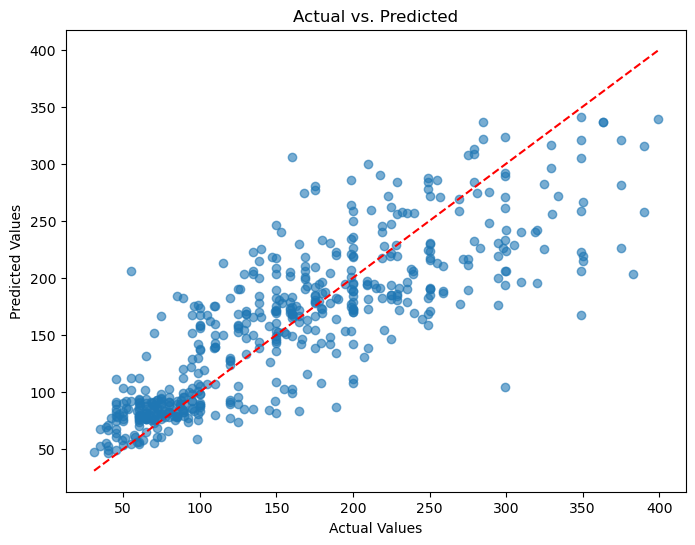

In [35]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], '--', color='red')
plt.title('Actual vs. Predicted')
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.show()

**Random Forest Regressor**

Performance Metrics:
- MAE: \$34.65
  - Random Forest had a slightly higher error compared to Linear Regression but still outperformed KNN.
- RMSE: \$46.74
  - The RMSE was slightly higher than Linear Regression, suggesting that the model had more variation in its predictions for higher-priced listings.
- R²: 0.70
  - The model explained 70% of the variance in prices, closely rivaling Linear Regression.

Actual vs. Predicted Scatter Plots:

The scatter plots for each model showed the relationship between actual prices (y_test) and predicted prices.

Random Forest: Points were slightly more scattered but still demonstrated strong predictive performance.

Observations:
- Random Forest demonstrated robust performance, particularly in capturing non-linear relationships and feature interactions that Linear Regression might have overlooked.
- The model's ability to provide feature importance insights was a significant advantage, revealing that key features such as room_type, number_of_bedrooms, and review_scores_rating had the most substantial influence on price predictions.
- While its predictions were slightly less accurate than Linear Regression, Random Forest is better equipped to handle datasets with more complexity and variability.

Interpretation:
- Random Forest effectively captured the complexity of the dataset, making it a strong alternative to Linear Regression. However, its slightly higher computational cost and marginally lower accuracy make it less optimal for this specific task.


#### Model Comparisons

In [36]:
# Dictionary to store results for each model
knn_results = {
    "MAE": mae_knn,
    "RMSE": rmse_knn,
    "R²": r2_knn
}

linear_reg_results = {
    "MAE": mae_linear_reg,
    "RMSE": rmse_linear_reg,
    "R²": r2_linear_reg
}

rf_results = {
    "MAE": mae_rf,
    "RMSE": rmse_rf,
    "R²": r2_rf
}

# Combine results from all models
all_results = [
    {"Model": "K-Nearest Neighbors (KNN)", **knn_results},
    {"Model": "Linear Regression", **linear_reg_results},
    {"Model": "Random Forest", **rf_results},
]

# Convert to DataFrame
results_df = pd.DataFrame(all_results)

# Display Results
print("\nModel Comparison Table:")
results_df


Model Comparison Table:


,Model,MAE,RMSE,R²
0,K-Nearest Neighbors (KNN),43.144328,56.939008,0.550043
1,Linear Regression,33.141037,44.751705,0.722047
2,Random Forest,34.653649,46.735121,0.696863


Comparison of Results
- Best Overall Performance: Linear Regression was the best-performing model, with the lowest errors (MAE and RMSE) and the highest R² score, indicating its ability to predict prices accurately while explaining the majority of the variance in the data.
- Robustness and Feature Insights: Random Forest provided valuable insights into feature importance and performed nearly as well as Linear Regression, making it a reliable alternative.
- Weakest Performance: KNN struggled with generalization due to its sensitivity to data scaling and local patterns.

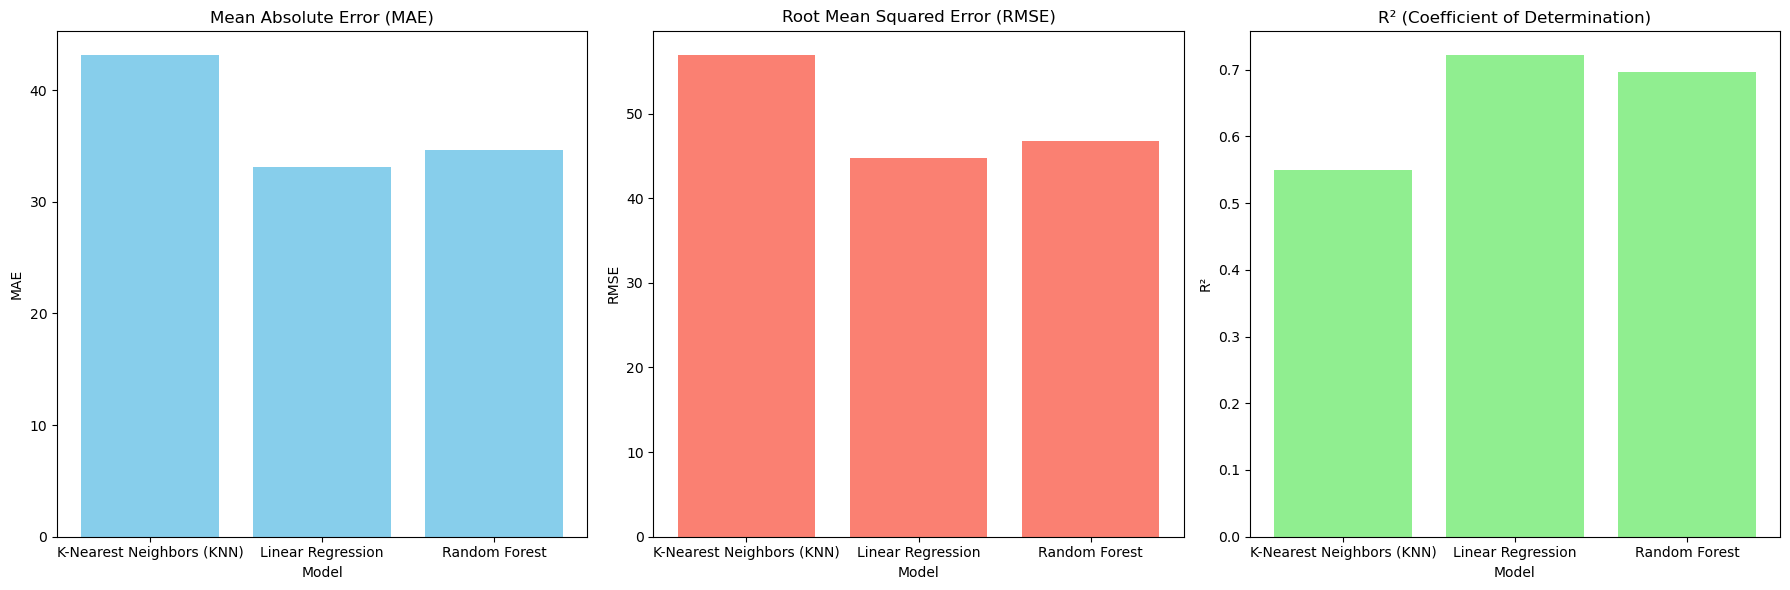

In [37]:
# Set up the plot size
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Plot MAE
axes[0].bar(results_df["Model"], results_df["MAE"], color='skyblue')
axes[0].set_title('Mean Absolute Error (MAE)')
axes[0].set_xlabel('Model')
axes[0].set_ylabel('MAE')

# Plot RMSE
axes[1].bar(results_df["Model"], results_df["RMSE"], color='salmon')
axes[1].set_title('Root Mean Squared Error (RMSE)')
axes[1].set_xlabel('Model')
axes[1].set_ylabel('RMSE')

# Plot R²
axes[2].bar(results_df["Model"], results_df["R²"], color='lightgreen')
axes[2].set_title('R² (Coefficient of Determination)')
axes[2].set_xlabel('Model')
axes[2].set_ylabel('R²')

# Display the plot
plt.tight_layout()
plt.show()

Bar Charts for Performance Metrics:

MAE, RMSE, and R² values were visualized side-by-side, making it clear that:
- Linear Regression consistently outperformed the other models.
- Random Forest followed closely, with competitive performance.
- KNN lagged significantly behind in all three metrics.

## Discussion

The analysis of the Airbnb Boston dataset using three machine learning models—K-Nearest Neighbors (KNN), Linear Regression, and Random Forest Regressor—highlighted significant differences in their performance, strengths, and limitations. Each model contributed unique insights, though their effectiveness varied based on the dataset's characteristics and the nature of the relationships between features and the target variable.

Linear Regression stood out as the best-performing model, achieving the lowest error rates (MAE = \$ 33.14, RMSE = \$ 44.75) and the highest explanatory power (R² = 0.72). Its simplicity and interpretability made it an ideal choice for this dataset, effectively capturing linear relationships between features such as room_type, number_of_bedrooms, and review_scores_rating and the target variable. The scatter plot of actual vs. predicted prices further confirmed its accuracy, with most points closely aligning along the ideal diagonal line. While Linear Regression assumes linearity, this limitation did not significantly affect its performance, as the dataset's features exhibited approximately linear relationships with price.

Random Forest Regressor also demonstrated strong performance, achieving an R² score of 0.70 and providing robust predictions. Its ability to capture non-linear relationships and feature interactions made it a valuable alternative to Linear Regression. One of its key advantages was the ability to rank feature importance, which revealed that room_type, number_of_bedrooms, and review_scores_rating were the most influential predictors of price. These insights offer actionable recommendations for Airbnb hosts, such as optimizing property amenities and enhancing guest satisfaction. However, Random Forest required more computational resources and hyperparameter tuning, which added complexity compared to Linear Regression.

In contrast, K-Nearest Neighbors (KNN) struggled to generalize effectively, with a high MAE of $43.14 and an R² score of 0.55. Its reliance on proximity in feature space and sensitivity to the choice of k made it less suitable for this dataset, particularly when dealing with higher-priced listings or outliers. While KNN can model non-linear relationships, its performance was limited by its dependency on feature scaling and its computational inefficiency, which hampers scalability for larger datasets.

Challenges encountered during the analysis included handling missing data, outliers, and the lack of temporal features such as seasonality. Missing values in key features like price and review_scores_rating required imputation or removal, which may have introduced bias. Outliers in the price column, particularly extremely high or low values, affected model performance, especially for KNN. Temporal features like seasonality or local events, which significantly influence Airbnb pricing, were not included in the dataset, limiting the models' ability to account for time-based variations.

In conclusion, Linear Regression emerged as the most effective model for predicting Airbnb prices in Boston due to its simplicity, accuracy, and interpretability. Random Forest proved to be a strong alternative, offering robust performance and valuable insights into feature importance. KNN, while intuitive, struggled with generalization and scalability. To improve future analyses, incorporating temporal and external data, such as seasonality, local events, and economic trends, and exploring advanced models could enhance predictive accuracy and provide deeper insights into pricing dynamics.

## Conclusion

This project successfully demonstrated the application of machine learning to predict the nightly prices of Airbnb listings in Boston. By leveraging key features such as room_type, number_of_bedrooms, review_scores_rating, and amenities, we developed models that provide actionable insights for both hosts and guests. Linear Regression emerged as the best-performing model, achieving the highest accuracy with the lowest errors, while Random Forest offered robust performance and valuable insights into feature importance. K-Nearest Neighbors, although intuitive, struggled to generalize effectively and was less suitable for this task.

The analysis highlighted the importance of factors such as property type, location, and guest reviews in determining listing prices. These findings can help hosts optimize pricing strategies and enhance their listings to attract more bookings. Similarly, the predictions enable guests to make better-informed decisions when choosing accommodations.

While the models performed well, challenges such as handling missing data, outliers, and the lack of temporal features like seasonality limited the analysis. Future work can address these limitations by incorporating external factors, temporal trends, and advanced modeling techniques such as Gradient Boosting or Neural Networks to further improve accuracy and insights.

In conclusion, this project underscores the potential of machine learning to enhance decision-making on platforms like Airbnb, benefiting both property owners and travelers by providing deeper insights into pricing dynamics.

## MARKING RUBRICS

### Component Title: Group Project (Code, Report)

| Criteria                        | Excellent (15-13)                                                                                   | Good (12-10)                                                                                   | Average (9-7)                                                                                | Need Improvement (6-4)                                                                                  | Poor (3-0)                                                                                   | Weight (%) | Marks |
|---------------------------------|-----------------------------------------------------------------------------------------------------|------------------------------------------------------------------------------------------------|---------------------------------------------------------------------------------------------|---------------------------------------------------------------------------------------------------------|---------------------------------------------------------------------------------------------|------------|-------|
| **AI learning knowledge and understanding** | Students demonstrate excellent technical & practical understanding of AI learning knowledge and data science pipeline. | Students demonstrate a good practical understanding of AI learning knowledge and the data science pipeline. | Students demonstrate an average understanding of AI learning knowledge and the data science pipeline. | Students demonstrate an insufficient understanding of AI learning knowledge and the data science pipeline. | Students fail to demonstrate an understanding of AI learning knowledge and the data science pipeline. | 15         |       |
| **The quality of Code & Report**           | Excellent programming practice is followed with very detailed documentation. The report provides a concise summary of what is accomplished with very detailed explanations and discussion. | Good programming practice is followed by documentation. The report provides a concise summary of what is accomplished with detailed explanations and discussion. | Good programming practice is followed by simple documentation. The report provides a summary of what is accomplished with explanations and discussion. | Programming practice is followed by simple documentation. The report provides a summary of what is accomplished with little explanation and discussion. | Programming practice is not followed with documentation. The report provides an unclear summary of what is accomplished with little explanation and discussion. | 15         |       |
| **TOTAL**                       |                                                                                                     |                                                                                                |                                                                                             |                                                                                                         |                                                                                             | **30**     |       |


## MARKING RUBRICS

### Component Title: Group Project (Presentation)

| Criteria                       | Excellent (10-9)                                                                                                     | Good (8-7)                                                                                                       | Average (6-5)                                                                                      | Need Improvement (4-3)                                                                                              | Poor (2-0)                                                                                       | Weight (%) | Marks |
|--------------------------------|---------------------------------------------------------------------------------------------------------------------|------------------------------------------------------------------------------------------------------------------|---------------------------------------------------------------------------------------------------|----------------------------------------------------------------------------------------------------------------------|---------------------------------------------------------------------------------------------------|------------|-------|
| **Content Delivery and Q&A**   | Project content was delivered clearly with strong findings.                                                         | Project content was delivered clearly with findings. Students can answer questions by the lecturer and students. | Project content was delivered clearly with findings. Students can answer most questions by the lecturer and students. | Project content was delivered clearly with inferior findings. Students can answer most questions by the lecturer and students. | Project content was not delivered clearly with inferior findings. Students cannot answer most questions by the lecturer and students. | 10         |       |
| **Teamwork & Peer Assessment** | All team worked well together to achieve objectives. Each member contributed in a valuable way to the project since the group was formed. | Almost all team worked well together to achieve objectives. Each member contributed in a valuable way to the project. | The team worked well together most of the time, with only a few occurrences of communication breakdown or failure to collaborate when appropriate. Members were mostly respectful of each other. | Few of the team worked together, with only a few occurrences of communication breakdown or failure to collaborate when appropriate. Few members were mostly respectful of each other. | The team did not collaborate or communicate well since the group formed. Some members would work independently, without regard to objectives or priorities. A lack of respect and regard was frequently noted. | 10         |       |
| **TOTAL**                      |                                                                                                                     |                                                                                                                  |                                                                                                   |                                                                                                                      |                                                                                                   | **20**     |       |
